# Laboratorio dirigido 12 — Analítica de procesos internos
**Caso:** monitoreo de la temperatura de una máquina industrial y priorización de alertas operativas.
**Datos reales:** Numenta Anomaly Benchmark (NAB), serie `machine_temperature_system_failure`: lecturas cada 5 minutos del sensor de temperatura de un componente interno de una máquina industrial grande, del 2 de diciembre de 2013 al 19 de febrero de 2014. La fuente no indica la unidad de medida.
**Pregunta:** ¿qué lecturas y qué días merecen revisión primero, sin acusar una falla a partir de una simple rareza estadística?

> Referencia: Lavin, A. y Ahmad, S. (2015). *Evaluating Real-Time Anomaly Detection Algorithms — The Numenta Anomaly Benchmark.* 14th IEEE International Conference on Machine Learning and Applications.

**Estudiante:** Jhadir Abdel Yupanqui Chahua · **Sección:** C28 6to A · TECSUP 2026-II.

**Uso de IA:** ChatGPT ayuda en la redacción de codigo.


## Objetivos y teoría
La detección de anomalías identifica observaciones poco habituales según un conjunto de variables. Isolation Forest produce una puntuación de rareza; el umbral se calibra exclusivamente con la línea base. La carta p monitorea la proporción diaria de lecturas en alerta con límites que dependen del número de lecturas de cada día. Una alerta es un motivo para investigar, no una prueba de falla.

Los autores de NAB señalan **ventanas de anomalía** en la serie. Se usan solo como referencia para contrastar las alertas **después** de calibrar el modelo: son ventanas aproximadas y las etiquetas no asignan una causa a cada intervalo. El README de NAB sí describe un apagado planificado y una secuencia que termina en falla catastrófica; no se atribuyen esas causas automáticamente a cada alerta.

## Paso 1. Cargar datos abiertos y conservar trazabilidad
Fuente de los datos: https://github.com/numenta/NAB/blob/master/data/realKnownCause/machine_temperature_system_failure.csv . Etiquetas: https://github.com/numenta/NAB/blob/master/labels/combined_windows.json . Licencia del repositorio: MIT (Numenta, 2014-2024).

In [1]:
# Dependencias del análisis; instalación solo si faltan (compatible con Colab).
import importlib.util
import subprocess
import sys
paquetes = {'numpy': 'numpy==2.5.0', 'pandas': 'pandas==2.2.3', 'matplotlib': 'matplotlib==3.11.0', 'sklearn': 'scikit-learn==1.9.0'}
faltan = [paquete for modulo, paquete in paquetes.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
import hashlib
import json
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import IsolationForest
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 75)
NAB_COMMIT = "ea702d75cc2258d9d7dd35ca8e5e2539d71f3140"
BASE_URL = f"https://raw.githubusercontent.com/numenta/NAB/{NAB_COMMIT}/"
URL_DATOS = BASE_URL + "data/realKnownCause/machine_temperature_system_failure.csv"
URL_ETIQ = BASE_URL + "labels/combined_windows.json"
DATOS = Path("datos")
RESULTADOS = Path("resultados")
DATOS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)
FUENTES = {'machine_temperature_system_failure.csv': {'url': 'https://raw.githubusercontent.com/numenta/NAB/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/data/realKnownCause/machine_temperature_system_failure.csv', 'sha256': '92bf5b87fc7f9bba8ca0b7ec63ccaac8cb4a1371a258e8c29a10ae9c018d82a4', 'bytes': 732223}, 'combined_windows.json': {'url': 'https://raw.githubusercontent.com/numenta/NAB/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/labels/combined_windows.json', 'sha256': '1e1fbc4601321aad8d0f8b3784c8134299379f68f6c1f7777565f8ffd57ab6b1', 'bytes': 15359}, 'LICENSE-NAB.txt': {'url': 'https://raw.githubusercontent.com/numenta/NAB/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/LICENSE.txt', 'sha256': '0a0b4d0b10cb1f7ed9ab2993ef93defc03447e6eba9daca1315dd32dae4877e3', 'bytes': 1056}, 'README-NAB.md': {'url': 'https://raw.githubusercontent.com/numenta/NAB/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/data/README.md', 'sha256': '1d32963e44a52323b44affff374a1222ebe5ef19ef8f7f6c6fd7a747aa52db30', 'bytes': 2931}}

def archivo_fuente(nombre):
    """Usa la copia local; en Colab descarga la misma versión y verifica su SHA-256."""
    destino = DATOS / nombre
    if not destino.exists():
        with urllib.request.urlopen(FUENTES[nombre]["url"], timeout=60) as respuesta:
            destino.write_bytes(respuesta.read())
    assert hashlib.sha256(destino.read_bytes()).hexdigest() == FUENTES[nombre]["sha256"], nombre
    return destino

raw = pd.read_csv(archivo_fuente("machine_temperature_system_failure.csv"), parse_dates=["timestamp"])
VERSIONES = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
             "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__}
print("Versiones de esta ejecución:", VERSIONES)
print("Fuente fijada al commit:", NAB_COMMIT)
print("Filas originales:", len(raw), "Columnas:", list(raw.columns))
print("Desde", raw.timestamp.min(), "hasta", raw.timestamp.max())
display(raw.head())


Versiones de esta ejecución: {'python': '3.12.10', 'numpy': '2.5.0', 'pandas': '2.2.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
Fuente fijada al commit: ea702d75cc2258d9d7dd35ca8e5e2539d71f3140
Filas originales: 22695 Columnas: ['timestamp', 'value']
Desde 2013-12-02 21:15:00 hasta 2014-02-19 15:25:00


,timestamp,value
0,2013-12-02 21:15:00,73.967322
1,2013-12-02 21:20:00,74.935882
2,2013-12-02 21:25:00,76.124162
3,2013-12-02 21:30:00,78.140707
4,2013-12-02 21:35:00,79.329836


**Lectura de los resultados:** Se cargan 22.695 filas del archivo original y se muestra su rango. La copia de datos se verifica mediante SHA-256 y conserva un commit fijo de la fuente; las versiones impresas documentan el entorno.

## Paso 2. Reglas de calidad y variables derivadas
Se retiran las marcas de tiempo repetidas (se conserva la primera), se ordena la serie y se trabaja con días completos: del 3 de diciembre de 2013 al 18 de febrero de 2014. Son reglas analíticas declaradas, no verdades de la fuente. Las variables derivadas usan únicamente el presente y el pasado: media y desviación de las últimas 12 lecturas (ventana nominal de una hora) y diferencia respecto de 12 intervalos atrás. Esta diferencia deja sin historia suficiente las primeras 12 filas. No se eliminan temperaturas bajas por parecer extrañas.

In [2]:
# Marcas de tiempo repetidas: se conserva la primera lectura de cada instante
repetidas = raw.timestamp.duplicated(keep="first")
df = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
# Se comprueba que todas las lecturas están separadas por 5 minutos
fuera_de_paso = int((df.index.to_series().diff().dropna().dt.total_seconds().ne(300)).sum())
# Solo días completos: el primer y el último día de la fuente están incompletos
df = df.loc["2013-12-03":"2014-02-18 23:59"].copy()
print("Marcas repetidas:", int(repetidas.sum()), "· lecturas útiles:", len(raw) - int(repetidas.sum()))
print("Lecturas fuera del paso de 5 min:", fuera_de_paso, "· lecturas en días completos:", len(df))
print(df.value.describe().round(2))
print("Lecturas por debajo de 20:", int((df.value < 20).sum()))
# Variables derivadas de la última hora; las 12 primeras lecturas no tienen historia suficiente
feat = pd.DataFrame({"valor": df.value,
                     "media_1h": df.value.rolling(12).mean(),
                     "desv_1h": df.value.rolling(12).std(),
                     "cambio_1h": df.value.diff(12)}).dropna()
print("Lecturas con variables completas:", len(feat))
# Auditoría explícita de calidad: huecos reales, bordes excluidos y no finitos.
unicos = raw.loc[~repetidas].sort_values("timestamp").set_index("timestamp")
calendario = pd.date_range(unicos.index.min(), unicos.index.max(), freq="5min")
huecos = calendario.difference(unicos.index)
calidad = {"filas_originales": len(raw), "repetidas": int(repetidas.sum()),
           "huecos": len(huecos), "fuera_de_paso": fuera_de_paso,
           "nulos": int(raw.isna().sum().sum()), "no_finitos_valor": int((~np.isfinite(raw.value)).sum()),
           "bordes_excluidos": len(unicos) - len(df), "dias_completos": df.index.normalize().nunique(),
           "filas_dias_completos": len(df), "filas_sin_historia": len(df) - len(feat),
           "filas_modelo": len(feat), "minimo": float(df.value.min()), "maximo": float(df.value.max()),
           "lecturas_menor20": int((df.value < 20).sum())}
display(pd.Series(calidad, name="resultado").to_frame())
assert not raw.isna().any().any() and np.isfinite(raw.value).all()
assert len(huecos) == 0 and fuera_de_paso == 0
assert df.groupby(df.index.normalize()).size().eq(288).all()
assert len(df) - len(feat) == 12
VARIABLES = ["valor", "media_1h", "desv_1h", "cambio_1h"]


Marcas repetidas: 12 · lecturas útiles: 22683
Lecturas fuera del paso de 5 min: 0 · lecturas en días completos: 22464
count    22464.00
mean        85.87
std         13.80
min          2.08
25%         83.03
50%         89.33
75%         94.00
max        108.51
Name: value, dtype: float64
Lecturas por debajo de 20: 12
Lecturas con variables completas: 22452


,resultado
filas_originales,22695.000000
repetidas,12.000000
huecos,0.000000
fuera_de_paso,0.000000
nulos,0.000000
no_finitos_valor,0.000000
bordes_excluidos,219.000000
dias_completos,78.000000
filas_dias_completos,22464.000000
filas_sin_historia,12.000000


**Lectura de los resultados:** Se retiran 12 marcas repetidas, sin huecos ni saltos de frecuencia. Se conservan 22.464 lecturas de 78 días completos y 22.452 con historia suficiente. Los 12 valores menores que 20 se conservan para investigar su origen.

## Paso 3. Separar línea base y periodo de seguimiento
Línea base: 3 al 31 de diciembre de 2013. Seguimiento: 1 de enero al 18 de febrero de 2014. La separación se fija antes de examinar las alertas. Las ventanas de NAB se cargan solo para contrastar los resultados.

In [3]:
CORTE = pd.Timestamp("2014-01-01")
base = feat.index < CORTE
# Ventanas de anomalía señaladas por los autores de NAB (solo referencia para contrastar)
etiquetas = json.loads(archivo_fuente("combined_windows.json").read_text(encoding="utf-8"))["realKnownCause/machine_temperature_system_failure.csv"]
ventanas = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in etiquetas]
en_ventana = pd.Series(False, index=feat.index)
for a, b in ventanas:
    en_ventana.loc[a:b] = True
print("Línea base:", int(base.sum()), "lecturas · Seguimiento:", int((~base).sum()), "lecturas")
print("Ventanas de referencia:", [(str(a)[:16], str(b)[:16]) for a, b in ventanas])
assert base.sum() > 5000 and (~base).sum() > 10000

Línea base: 8340 lecturas · Seguimiento: 14112 lecturas
Ventanas de referencia: [('2013-12-10 06:25', '2013-12-12 05:35'), ('2013-12-15 17:50', '2013-12-17 17:00'), ('2014-01-27 14:20', '2014-01-29 13:30'), ('2014-02-07 14:55', '2014-02-09 14:05')]


**Lectura de los resultados:** Quedan 8.340 lecturas base y 14.112 de seguimiento. Dos de las cuatro ventanas NAB están en diciembre: la línea base histórica no equivale a un conjunto certificado libre de anomalías. Las etiquetas no intervienen en el ajuste ni en el percentil.

## Paso 4. Detectar lecturas inusuales
El bosque se ajusta solo con la línea base. Una puntuación mayor significa una lectura más atípica. El percentil 99 de la puntuación base fija la alerta principal. El modelo aprende patrones estadísticos; no conoce la causa física de una lectura.

In [4]:
modelo = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
# El modelo aprende lo normal solo con la línea base
modelo.fit(feat.loc[base, VARIABLES])
# Puntuación de rareza: mayor valor significa lectura más atípica
feat["score"] = -modelo.score_samples(feat[["valor", "media_1h", "desv_1h", "cambio_1h"]])
# Umbral: percentil 99 de las puntuaciones de la línea base
umbral = feat.loc[base, "score"].quantile(0.99)
feat["alerta"] = feat.score >= umbral
print("Umbral:", round(umbral, 4))
print("Alertas en la línea base:", int(feat.loc[base, "alerta"].sum()))
print("Alertas en el seguimiento:", int(feat.loc[~base, "alerta"].sum()))

Umbral: 0.606
Alertas en la línea base: 84
Alertas en el seguimiento: 495


**Lectura de los resultados:** El umbral p99 es 0,606017; genera 84 alertas base y 495 de seguimiento. Se utiliza la puntuación negativa de score_samples para que una cifra mayor signifique más rareza; esa cifra no es una probabilidad de avería.

## Paso 5. Carta p con límites diarios
La proporción base p̄ es el total de alertas base dividido por el total de lecturas base. Cada límite superior usa el número n de lecturas del día. Se muestran todos los días, pero la evaluación de señales fuera de control se hace sobre el seguimiento. Las lecturas contiguas están correlacionadas, de modo que el supuesto binomial es una aproximación.

In [5]:
diario = feat.groupby(feat.index.normalize()).agg(lecturas=("alerta", "size"), alertas=("alerta", "sum"))
pbar = feat.loc[base, "alerta"].mean()
diario["tasa"] = diario.alertas / diario.lecturas
diario["lsc"] = np.minimum(1, pbar + 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["lic"] = np.maximum(0, pbar - 3 * np.sqrt(pbar * (1 - pbar) / diario.lecturas))
diario["fuera"] = (diario.tasa > diario.lsc) | (diario.tasa < diario.lic)
seguimiento = diario.loc[CORTE:].copy()
print("p̄ =", round(pbar, 5))
print(seguimiento[["lecturas", "alertas", "tasa", "lsc", "fuera"]].query("alertas > 0").to_string())
print("Días fuera de control en el seguimiento:", [str(d)[:10] for d in seguimiento.index[seguimiento.fuera]])
print("Días de la línea base fuera de límites:", int(diario.loc[diario.index < CORTE, "fuera"].sum()), "de", int((diario.index < CORTE).sum()))

p̄ = 0.01007
            lecturas  alertas      tasa       lsc  fuera
timestamp                                               
2014-01-02       288        5  0.017361  0.027724  False
2014-01-05       288        8  0.027778  0.027724   True
2014-01-12       288       13  0.045139  0.027724   True
2014-01-16       288        8  0.027778  0.027724   True
2014-01-24       288       12  0.041667  0.027724   True
2014-01-31       288        1  0.003472  0.027724  False
2014-02-03       288       25  0.086806  0.027724   True
2014-02-07       288        5  0.017361  0.027724  False
2014-02-08       288      246  0.854167  0.027724   True
2014-02-09       288      158  0.548611  0.027724   True
2014-02-13       288        8  0.027778  0.027724   True
2014-02-14       288        6  0.020833  0.027724  False
Días fuera de control en el seguimiento: ['2014-01-05', '2014-01-12', '2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']
Días de la línea base fuera de lími

**Lectura de los resultados:** Ocho días del seguimiento rebasan el LSC aproximado de 2,7724 %. La propia base presenta tres días fuera, de modo que no se puede asumir estabilidad estadística solo por haber elegido ese periodo.

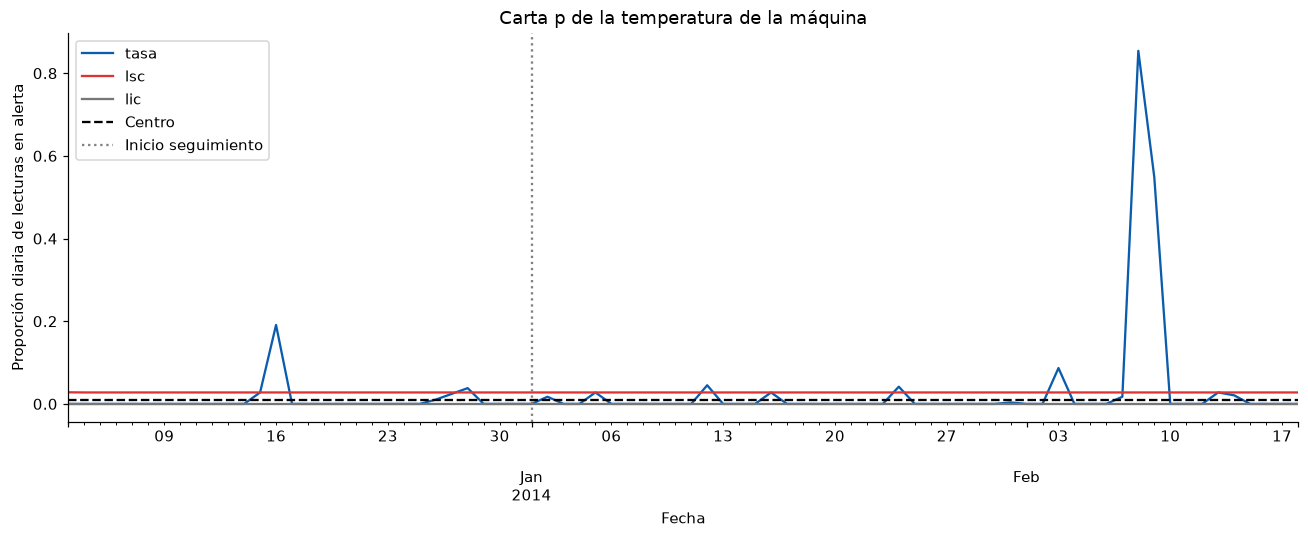

In [6]:
ax = diario[["tasa", "lsc", "lic"]].plot(figsize=(12, 5), color=["#0B5CAD", "#D33", "#777"])
ax.axhline(pbar, color="black", ls="--", label="Centro")
ax.axvline(CORTE, color="gray", ls=":", label="Inicio seguimiento")
ax.set(ylabel="Proporción diaria de lecturas en alerta", xlabel="Fecha", title="Carta p de la temperatura de la máquina")
ax.legend(); plt.tight_layout()
plt.savefig(RESULTADOS / "01_carta_p.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura de los resultados:** Destacan el 8 y 9 de febrero, con 85,42 % y 54,86 % de lecturas en alerta. El cambio de proporción orienta la prioridad de revisión; la causa no se obtiene de la carta.

## Paso 6. Convertir alertas en una cola de revisión
Un **episodio** agrupa las alertas separadas por 30 minutos o menos: es la unidad que el equipo revisa. La capacidad de **1 episodio por día** es un **supuesto académico**. La prioridad es la puntuación máxima del episodio. Se calcula la cola y se contrasta con las ventanas de NAB: un episodio coincide con una ventana si se superponen en el tiempo.

**Alcance de la capacidad:** la regla guiada selecciona hasta un episodio por día de inicio, con su máximo retrospectivo. «En cola» significa excedente de esa capacidad diaria; no simula atención de pendientes en días posteriores. Como el máximo y el fin solo se conocen después, no representa un despacho en tiempo real. Se calcula también una cola FIFO que sí arrastra pendientes para distinguir ambas lecturas.

In [7]:
CAPACIDAD_DIA = 1
alertas = feat.loc[feat.alerta, ["score"]].reset_index()
# Un episodio nuevo empieza cuando pasan más de 30 minutos desde la alerta anterior
alertas["episodio"] = (alertas.timestamp.diff().dt.total_seconds().gt(1800)).cumsum()
episodios = alertas.groupby("episodio").agg(inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                            lecturas=("score", "size"), score_max=("score", "max"))
episodios["dia"] = episodios.inicio.dt.normalize()
# Coincidencia con una ventana de referencia: superposición en el tiempo
episodios["en_ventana"] = [any((i <= b) and (f >= a) for a, b in ventanas) for i, f in zip(episodios.inicio, episodios.fin)]
ep = episodios[episodios.inicio >= CORTE].copy()
# Prioridad dentro de cada día por puntuación máxima; se revisan los primeros hasta completar la capacidad
ep["orden_dia"] = ep.groupby("dia").score_max.rank(method="first", ascending=False)
ep["revisable"] = ep.orden_dia <= CAPACIDAD_DIA
print("Episodios en el seguimiento:", len(ep), "· revisables:", int(ep.revisable.sum()), "· en cola:", int((~ep.revisable).sum()))
print("Episodios que coinciden con una ventana:", int(ep.en_ventana.sum()))
print("Lecturas en alerta dentro de ventanas:", int((feat.loc[~base, "alerta"] & en_ventana[~base]).sum()), "de", int(feat.loc[~base, "alerta"].sum()))
display(ep.sort_values("score_max", ascending=False).head(10).round(3))
ep["duracion_min"] = (ep.fin - ep.inicio).dt.total_seconds() / 60
top10 = ep.sort_values(["score_max", "inicio"], ascending=[False, True]).head(10)
display(top10[["inicio", "fin", "duracion_min", "lecturas", "score_max", "en_ventana", "revisable"]])


Episodios en el seguimiento: 17 · revisables: 11 · en cola: 6
Episodios que coinciden con una ventana: 2
Lecturas en alerta dentro de ventanas: 404 de 495


,inicio,fin,lecturas,score_max,dia,en_ventana,orden_dia,revisable
episodio,,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,403,0.793,2014-02-08,True,1.0,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,17,0.761,2014-02-03,False,1.0,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,12,0.679,2014-01-24,False,1.0,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,8,0.660,2014-02-03,False,2.0,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,8,0.644,2014-01-12,False,1.0,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,4,0.640,2014-02-13,False,1.0,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,5,0.640,2014-01-12,False,2.0,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,6,0.637,2014-01-16,False,1.0,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,8,0.634,2014-01-05,False,1.0,True


,inicio,fin,duracion_min,lecturas,score_max,en_ventana,revisable
episodio,,,,,,,
18,2014-02-08 02:40:00,2014-02-09 13:05:00,2065.0,403,0.793347,True,True
15,2014-02-03 11:50:00,2014-02-03 13:10:00,80.0,17,0.760964,False,True
12,2014-01-24 12:50:00,2014-01-24 13:45:00,55.0,12,0.679232,False,True
14,2014-02-03 00:10:00,2014-02-03 00:45:00,35.0,8,0.660254,False,False
9,2014-01-12 09:35:00,2014-01-12 10:10:00,35.0,8,0.644356,False,True
19,2014-02-13 19:30:00,2014-02-13 19:45:00,15.0,4,0.640436,False,True
8,2014-01-12 08:25:00,2014-01-12 08:45:00,20.0,5,0.639655,False,False
11,2014-01-16 13:00:00,2014-01-16 13:25:00,25.0,6,0.636535,False,True
7,2014-01-05 17:50:00,2014-01-05 18:25:00,35.0,8,0.634092,False,True


**Lectura de los resultados:** Las 495 alertas forman 17 episodios. Once caben en el cupo del día de inicio y seis lo exceden. Dos episodios coinciden con la misma ventana, y 404 de las 495 lecturas en alerta caen dentro de ventanas de seguimiento.

## Paso 7. Sensibilidad del umbral
Compare los percentiles base 98, 99 y 99,5. Para cada uno reporte alertas de seguimiento, episodios, episodios que coinciden con una ventana, días fuera de control y cola con la capacidad de 1 episodio por día. El umbral se calcula siempre en la línea base.

In [8]:
# Una misma evaluación para los escenarios: nunca reentrena con el seguimiento.
def evaluar(scores, corte, q=0.99):
    mascara_base = scores.index < corte
    umbral_local = float(scores[mascara_base].quantile(q))
    alerta_local = scores >= umbral_local
    p_base = float(alerta_local[mascara_base].mean())
    dias = alerta_local.groupby(alerta_local.index.normalize()).agg(["size", "sum"])
    dias.columns = ["lecturas", "alertas"]
    dias["tasa"] = dias.alertas / dias.lecturas
    amplitud = 3 * np.sqrt(p_base * (1 - p_base) / dias.lecturas)
    dias["lsc"] = np.minimum(1, p_base + amplitud)
    dias["lic"] = np.maximum(0, p_base - amplitud)
    dias["fuera"] = (dias.tasa > dias.lsc) | (dias.tasa < dias.lic)
    # Agrupación original: cortes si dos alertas consecutivas distan más de 30 min.
    alertas_local = scores.loc[alerta_local].rename("score").reset_index()
    alertas_local["episodio"] = (alertas_local.timestamp.diff().dt.total_seconds().gt(1800)).cumsum()
    episodios_local = alertas_local.groupby("episodio").agg(
        inicio=("timestamp", "min"), fin=("timestamp", "max"),
        lecturas=("score", "size"), score_max=("score", "max"))
    episodios_local = episodios_local.loc[episodios_local.inicio >= corte].copy()
    episodios_local["dia"] = episodios_local.inicio.dt.normalize()
    episodios_local["en_ventana"] = [any(i <= b and f >= a for a, b in ventanas)
        for i, f in zip(episodios_local.inicio, episodios_local.fin)]
    episodios_local["orden_dia"] = episodios_local.groupby("dia").score_max.rank(method="first", ascending=False)
    episodios_local["revisable"] = episodios_local.orden_dia <= CAPACIDAD_DIA
    ventanas_seg = [(a, b) for a, b in ventanas if b >= corte]
    cubiertas = sum(any((episodios_local.inicio <= b) & (episodios_local.fin >= max(a, corte))) for a, b in ventanas_seg)
    resumen = {"percentil_base": q, "umbral": umbral_local, "p_base": p_base,
        "lecturas_seguimiento": int((~mascara_base).sum()),
        "alertas": int(alerta_local[~mascara_base].sum()), "episodios": len(episodios_local),
        "en_ventana": int(episodios_local.en_ventana.sum()),
        "ventanas_cubiertas": int(cubiertas), "ventanas_evaluables": len(ventanas_seg),
        "dias_fuera": int(dias.loc[corte:, "fuera"].sum()),
        "revisables": int(episodios_local.revisable.sum()),
        "cola": int((~episodios_local.revisable).sum())}
    return resumen, dias, episodios_local, alerta_local

escenarios = {q: evaluar(feat.score, CORTE, q) for q in [0.98, 0.99, 0.995]}
sensibilidad = pd.DataFrame([resultado[0] for resultado in escenarios.values()])
display(sensibilidad.round(6))
assert escenarios[0.99][0]["alertas"] == int(feat.loc[~base, "alerta"].sum())
assert escenarios[0.99][0]["episodios"] == len(ep)
assert escenarios[0.99][0]["dias_fuera"] == int(seguimiento.fuera.sum())

# Cola FIFO adicional: llegan al cierre de cada día de inicio y se atienden pendientes.
# Es una simulación por lotes diarios, no un sistema en tiempo real ni el criterio score_max.
filas_fifo = []
for q, (_, _, eps, _) in escenarios.items():
    pendientes, maximo, revisadas = 0, 0, 0
    llegadas = eps.groupby("dia").size()
    for dia in seguimiento.index:
        pendientes += int(llegadas.get(dia, 0))
        maximo = max(maximo, pendientes)
        atendidas = min(CAPACIDAD_DIA, pendientes)
        pendientes -= atendidas
        revisadas += atendidas
    filas_fifo.append({"percentil_base": q, "revisadas_FIFO": revisadas,
                       "pendientes_final_FIFO": pendientes, "maximo_antes_servicio": maximo})
fifo = pd.DataFrame(filas_fifo)
display(fifo)


,percentil_base,umbral,p_base,lecturas_seguimiento,alertas,episodios,en_ventana,ventanas_cubiertas,ventanas_evaluables,dias_fuera,revisables,cola
0,0.980,0.559949,0.020024,14112,686,31,4,2,2,11,16,15
1,0.990,0.606017,0.010072,14112,495,17,2,1,2,8,11,6
2,0.995,0.692755,0.005036,14112,31,3,2,1,2,3,3,0


,percentil_base,revisadas_FIFO,pendientes_final_FIFO,maximo_antes_servicio
0,0.980,31,0,6
1,0.990,17,0,3
2,0.995,3,0,1


**Lectura de los resultados:** Los umbrales p98/p99/p99,5 generan 31/17/3 episodios y 15/6/0 excedentes diarios. La simulación FIFO, que sí atiende pendientes en días posteriores, termina sin cola en los tres casos: las dos definiciones responden preguntas distintas.

## Tres retos individuales — diez ítems
Responda cada pregunta con sus propias palabras y con las cifras de su ejecución.

### Pregunta 1.1
Cuantifique las marcas repetidas, los huecos y el rango de la serie, y explique dos causas posibles de las lecturas muy bajas.

**Respuesta:**

La fuente contiene **22.695 filas** entre **2013-12-02 21:15:00 y 2014-02-19 15:25:00**, con dos columnas. Hay **12 marcas repetidas**: conservo la primera lectura de cada instante y quedan 22.683 marcas únicas. No hay huecos en el calendario de 5 minutos, saltos fuera de esa frecuencia, nulos ni valores no finitos. Que no haya huecos no garantiza que el sensor mida bien.

Para comparar días completos excluyo **219 lecturas de los bordes**: quedan **22.464 lecturas en 78 días**, del 03/12/2013 al 18/02/2014. El mínimo es **2,0847** y el máximo **108,5105**, sin asignar una unidad que la fuente no documenta. Hay **12 lecturas menores que 20**; no las borro por ese solo motivo. Las variables de historia dejan fuera otras 12 filas y el modelo usa **22.452**.

Dos hipótesis para valores muy bajos son **un apagado o reducción de carga que enfría el componente**, y **una desconexión, pérdida de calibración o lectura defectuosa del sensor**. El README de NAB menciona un apagado planificado en el historial y una secuencia de fallas, pero eso no identifica la causa de cada lectura baja. Se debe contrastar con operación y mantenimiento. [Descripción original de los datos](https://github.com/numenta/NAB/blob/ea702d75cc2258d9d7dd35ca8e5e2539d71f3140/data/README.md).

### Pregunta 1.2
Describa dos episodios del top 10 con cifras (inicio, duración, lecturas en alerta y puntuación) y dos explicaciones operativas posibles para cada uno.

**Respuesta:**

Tomo los dos episodios de mayor puntuación del seguimiento:

| Episodio | Inicio | Fin | Duración entre extremos | Lecturas en alerta | Score máximo | Solapa ventana NAB |
| --- | --- | --- | --- | --- | --- | --- |
| 18 | 2014-02-08 02:40:00 | 2014-02-09 13:05:00 | 34 h 25 min (2.065 min) | 403 | 0,793347 | Sí |
| 15 | 2014-02-03 11:50:00 | 2014-02-03 13:10:00 | 1 h 20 min (80 min) | 17 | 0,760964 | No |

En el episodio **18** investigaría tanto **una parada prolongada o un cambio del régimen de carga/refrigeración** como **una alteración sostenida de la medición**. Su duración y 403 lecturas justifican revisar primero ese intervalo. En el episodio **15** contrastaría **una transición breve de carga, encendido o ajuste operativo** y **un transitorio de sensor o comunicación**. Son hipótesis, no diagnósticos.

La duración es `fin − inicio`, no el número de alertas multiplicado por cinco: un episodio puede incluir intervalos sin alerta siempre que no se separen más de 30 minutos. El score mide rareza relativa, no probabilidad de falla. El episodio 15 queda fuera de las ventanas etiquetadas, lo que tampoco demuestra que sea una falsa alarma.

### Pregunta 1.3
Identifique los días fuera de control e indique por qué son señales para investigar.

**Respuesta:**

En el seguimiento aparecen **8 días por encima del límite superior**:

| Fecha | Lecturas | Alertas | Tasa de alerta |
| --- | --- | --- | --- |
| 2014-01-05 | 288 | 8 | 2,78 % |
| 2014-01-12 | 288 | 13 | 4,51 % |
| 2014-01-16 | 288 | 8 | 2,78 % |
| 2014-01-24 | 288 | 12 | 4,17 % |
| 2014-02-03 | 288 | 25 | 8,68 % |
| 2014-02-08 | 288 | 246 | 85,42 % |
| 2014-02-09 | 288 | 158 | 54,86 % |
| 2014-02-13 | 288 | 8 | 2,78 % |

La línea central es **p̄ = 0,010072 (1,0072 %)**. Con 288 lecturas por día, el LSC es **2,7724 %** y el LIC es 0. Por eso incluso 8/288 = 2,7778 % rebasa ligeramente el LSC; el 08/02 alcanza 246/288 = 85,42 %.

Son señales para investigar porque la proporción excede la referencia calibrada, pero no identifican causa ni confirman una avería. Además, **3 de 29 días de la propia línea base** quedan fuera de límites y esa base incluye dos ventanas NAB. La autocorrelación de `valor` a un intervalo en la base es **0,9964**: las lecturas son muy dependientes y comparten ventanas móviles. La aproximación binomial de la carta p no garantiza aquí una tasa nominal de falsas alarmas.

### Pregunta 1.4
Proponga tres verificaciones externas antes de concluir una falla.

**Respuesta:**

Antes de concluir una falla haría tres verificaciones:

1. **Bitácora operativa y registros de control:** cruzar la fecha exacta con encendidos, apagados, cambios de carga, consignas y mantenimiento programado. Una parada autorizada puede explicar un descenso sin que exista avería.
2. **Validación de instrumentación:** contrastar con otro sensor o medición independiente, revisar calibración, alimentación, cableado y sincronización del registro. Esto distingue un cambio físico de un problema de medición o transmisión.
3. **Evidencia física y desempeño:** pedir a mantenimiento inspección del componente y comparar vibración, corriente, presión, producción y registros de reparación disponibles. Solo un diagnóstico documentado que explique el evento permite sostener una falla; el notebook no dispone de esa evidencia.

### Pregunta 2.1
Compare los tres umbrales con alertas, episodios, días fuera de control y cola.

**Respuesta:**

Mantengo el mismo modelo, las mismas 14.112 lecturas de seguimiento y los umbrales calculados exclusivamente en las 8.340 lecturas base:

| Percentil base | Umbral | Alertas | Episodios | Episodios en ventanas | Ventanas cubiertas | Días fuera | Revisables ese día | Excedente diario |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 98,0 | 0,559949 | 686 | 31 | 4 | 2/2 | 11 | 16 | 15 |
| 99,0 | 0,606017 | 495 | 17 | 2 | 1/2 | 8 | 11 | 6 |
| 99,5 | 0,692755 | 31 | 3 | 2 | 1/2 | 3 | 3 | 0 |

Al subir de p98 a p99,5 bajan las alertas **686 → 31**, los episodios **31 → 3** y los días fuera **11 → 3**. El percentil más alto reduce carga, pero solo cubre **una de las dos ventanas** de seguimiento. El número de episodios coincidentes tampoco equivale al número de fallas: dos episodios pueden caer en una sola ventana.

La «cola» de la guía suma excedentes del cupo en cada día de inicio y no los atiende después. Con una simulación adicional FIFO que sí arrastra pendientes y presta un servicio al cierre de cada día, los tres escenarios terminan con **0 pendientes**; los máximos antes del servicio son **6, 3 y 1**, respectivamente. Por tanto, 15/6/0 son sobrecargas diarias, no tamaños de la cola final. Ambas simulaciones son retrospectivas: los episodios se conocen completos después de ocurrir.

### Pregunta 2.2
Defienda un umbral bajo 1 revisión por día y declare el costo de oportunidad.

**Respuesta:**

Con el supuesto estricto de **una revisión por día de inicio y necesidad de evitar acumulación el mismo día**, elegiría **p99,5 (0,692755) para un piloto de priorización**, manteniendo p99 como referencia del ejercicio. En este historial produce **31 alertas, 3 episodios y 0 excedentes diarios**; los tres episodios caben en la capacidad asumida. No se ha optimizado un costo monetario porque faltan el costo de omitir un evento y el de investigarlo.

El costo de oportunidad frente a p99 es dejar fuera **464 lecturas en alerta**, pasar de **17 a 3 episodios** y de **8 a 3 días fuera**. Frente a p98 se pasa de **dos ventanas cubiertas a una**. Los episodios no se emparejan uno a uno entre umbrales, por lo que esas diferencias de conteos no identifican exactamente qué eventos físicos se pierden. No recomendaría usar p99,5 como única barrera de seguridad.

La elección favorece una carga manejable, no demuestra una detección óptima. Si se permite arrastrar pendientes, FIFO vacía la cola incluso con p98: entonces la capacidad agregada no basta para justificar el percentil alto y habría que comparar demoras y costos. Esta preferencia se formula tras observar la sensibilidad, así que requeriría validación en un periodo nuevo antes de adoptarse.

### Pregunta 2.3
Para cada ventana de referencia del seguimiento, calcule cuántas horas antes o después de su inicio apareció el primer episodio y explique por qué esa diferencia no demuestra capacidad de predicción.

In [9]:
# Ventanas del seguimiento: primer episodio que se solapa, incluido el que empezó antes.
# Si la ventana empieza en la línea base, solo se evalúa su porción de seguimiento.
filas_ventanas = []
for numero, (a, b) in enumerate(ventanas, 1):
    if b < CORTE:
        continue
    candidatos = ep.loc[(ep.inicio <= b) & (ep.fin >= max(a, CORTE))].sort_values("inicio")
    primero = candidatos.iloc[0] if not candidatos.empty else None
    posteriores = ep.loc[ep.inicio >= max(a, CORTE)].sort_values("inicio")
    primer_posterior = posteriores.iloc[0] if not posteriores.empty else None
    filas_ventanas.append({"ventana": numero, "inicio_ventana": a, "fin_ventana": b,
        "inicio_primer_episodio": primero.inicio if primero is not None else pd.NaT,
        "fin_primer_episodio": primero.fin if primero is not None else pd.NaT,
        "delta_horas": (primero.inicio - a).total_seconds()/3600 if primero is not None else np.nan,
        "episodios_solapados": len(candidatos),
        "primero_posterior_a_inicio": primer_posterior.inicio if primer_posterior is not None else pd.NaT,
        "delta_posterior_horas": (primer_posterior.inicio-a).total_seconds()/3600 if primer_posterior is not None else np.nan,
        "posterior_dentro_ventana": bool(primer_posterior.inicio <= b) if primer_posterior is not None else False})
demoras = pd.DataFrame(filas_ventanas)
display(demoras)
print("Delta negativo = inicio anterior; positivo = posterior; NaN = sin episodio solapado.")


,ventana,inicio_ventana,fin_ventana,inicio_primer_episodio,fin_primer_episodio,delta_horas,episodios_solapados,primero_posterior_a_inicio,delta_posterior_horas,posterior_dentro_ventana
0,3,2014-01-27 14:20:00,2014-01-29 13:30:00,NaT,NaT,NaN,0,2014-01-31 10:20:00,92.000000,False
1,4,2014-02-07 14:55:00,2014-02-09 14:05:00,2014-02-08 02:00:00,2014-02-08 02:00:00,11.083333,2,2014-02-08 02:00:00,11.083333,True


Delta negativo = inicio anterior; positivo = posterior; NaN = sin episodio solapado.


**Lectura de los resultados:** La ventana de enero no contiene episodios p99. La de febrero tiene dos: el primero empieza 11 horas y 5 minutos después del inicio de la ventana. La alerta y la atención efectiva no son lo mismo.

**Respuesta:**

Defino «primer episodio de la ventana» como el primero que **se solapa con ella**. También calculo el primer episodio posterior a su inicio aunque quede fuera, para no presentar una ausencia como detección:

| Ventana de seguimiento | Primer episodio solapado | Diferencia respecto del inicio | Interpretación |
|---|---|---|---|
| 27/01/2014 14:20 – 29/01/2014 13:30 | Ninguno | No disponible | La ventana no fue detectada por p99. El primer episodio posterior empieza el 31/01 a las 10:20, **92 horas después** del inicio, ya fuera de la ventana. |
| 07/02/2014 14:55 – 09/02/2014 14:05 | Episodio 17, 08/02/2014 02:00 | **+11,0833 h = 11 h 05 min después** | Una alerta aislada que no entra en el cupo diario frente al episodio 18. Este último empieza a las 02:40, **11 h 45 min después** del inicio de la ventana. |

No hay anticipación demostrada en estas dos ventanas. Una diferencia negativa, si existiera, solo indicaría que un episodio empezó antes de un intervalo anotado retrospectivamente. Las ventanas son amplias, no fechas exactas de avería; el modelo detecta rareza presente y no predice un fallo futuro. Además, la prioridad usa el score máximo del episodio completo: el inicio de una alerta no es la hora de revisión ni la hora en que se conoció ese máximo. La coincidencia temporal por sí sola no acredita causalidad ni capacidad predictiva.

### Pregunta 3.1
Repita la carta p con una línea base ampliada del 3 de diciembre al 15 de enero, reentrenando el modelo, e informe cambios.

,escenario,lecturas,alertas,episodios,dias_fuera,en_ventana,revisables,cola
0,Original | 01 ene–18 feb,14112,495,17,8,2,11,6
1,Original | 16 ene–18 feb,9792,469,13,6,2,8,5
2,Ampliado | 16 ene–18 feb,9792,501,16,6,2,10,6


Lecturas de base original / ampliada: 8340 12660
Umbral original / ampliado: 0.6060169567453604 0.5997241997494632
p base original / ampliada: 0.010071942446043165 0.010031595576619274
Días fuera, base ampliada: 7
Días fuera en seguimiento ampliado: ['2014-01-16', '2014-01-24', '2014-02-03', '2014-02-08', '2014-02-09', '2014-02-13']


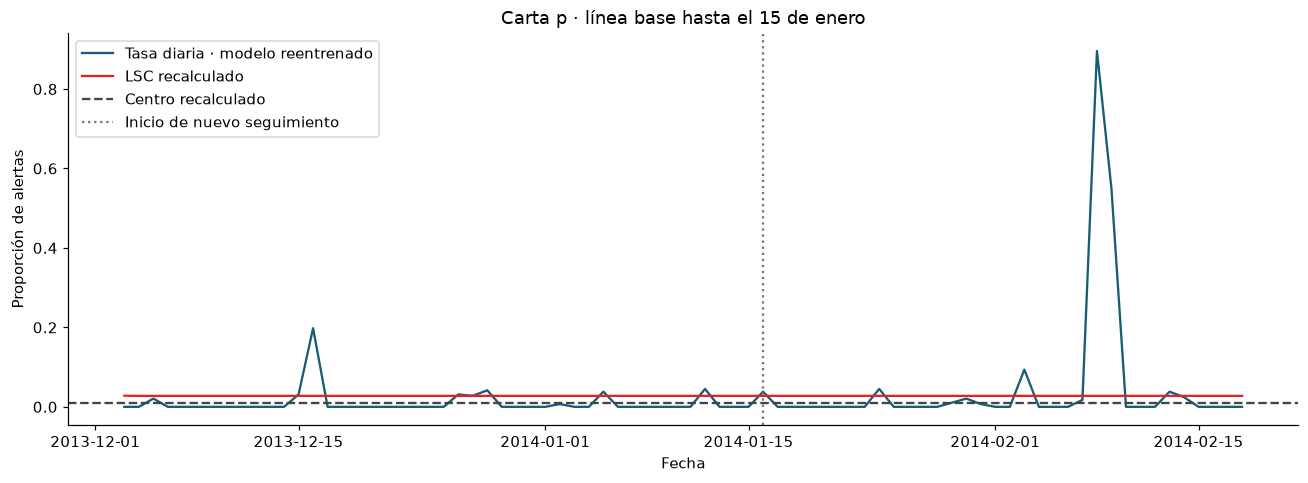

In [10]:
# Reto 3.1: reentrenar, recalibrar p99 y recalcular límites con la base ampliada.
CORTE_AMPLIADO = pd.Timestamp("2014-01-16")  # incluye todo el 15 de enero
base_ampliada = feat.index < CORTE_AMPLIADO
modelo_ampliado = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
modelo_ampliado.fit(feat.loc[base_ampliada, VARIABLES])
score_ampliado = pd.Series(-modelo_ampliado.score_samples(feat[VARIABLES]), index=feat.index)
res_ampliado, diario_ampliado, ep_ampliado, alerta_ampliada = evaluar(score_ampliado, CORTE_AMPLIADO)
res_original_comun, diario_original_comun, ep_original_comun, alerta_original_comun = evaluar(feat.score, CORTE)
def resumen_periodo(nombre, scores, dias, episodios_modelo, limite, fin=None):
    periodo = (scores.index >= limite)
    if fin is not None:
        periodo &= scores.index < fin
    ds = dias.loc[limite:] if fin is None else dias.loc[(dias.index >= limite) & (dias.index < fin)]
    eps = episodios_modelo.loc[episodios_modelo.inicio >= limite]
    if fin is not None:
        eps = eps.loc[eps.inicio < fin]
    return {"escenario": nombre, "lecturas": int(periodo.sum()),
        "alertas": int(scores[periodo].sum()), "episodios": len(eps),
        "dias_fuera": int(ds.fuera.sum()), "en_ventana": int(eps.en_ventana.sum()),
        "revisables": int(eps.revisable.sum()), "cola": int((~eps.revisable).sum())}
comparacion_base = pd.DataFrame([
    resumen_periodo("Original | 01 ene–18 feb", feat.alerta, diario, ep, CORTE),
    resumen_periodo("Original | 16 ene–18 feb", feat.alerta, diario, ep, CORTE_AMPLIADO),
    resumen_periodo("Ampliado | 16 ene–18 feb", alerta_ampliada, diario_ampliado, ep_ampliado, CORTE_AMPLIADO)])
display(comparacion_base)
print("Lecturas de base original / ampliada:", int(base.sum()), int(base_ampliada.sum()))
print("Umbral original / ampliado:", float(umbral), res_ampliado["umbral"])
print("p base original / ampliada:", float(pbar), res_ampliado["p_base"])
print("Días fuera, base ampliada:", int(diario_ampliado.loc[diario_ampliado.index < CORTE_AMPLIADO, "fuera"].sum()))
print("Días fuera en seguimiento ampliado:", diario_ampliado.loc[CORTE_AMPLIADO:].query("fuera").index.strftime("%Y-%m-%d").tolist())
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(diario_ampliado.index, diario_ampliado.tasa, label="Tasa diaria · modelo reentrenado", color="#155e75")
ax.plot(diario_ampliado.index, diario_ampliado.lsc, color="#dc2626", label="LSC recalculado")
ax.axhline(res_ampliado["p_base"], ls="--", color="#444444", label="Centro recalculado")
ax.axvline(CORTE_AMPLIADO, ls=":", color="#777777", label="Inicio de nuevo seguimiento")
ax.set(title="Carta p · línea base hasta el 15 de enero", xlabel="Fecha", ylabel="Proporción de alertas")
ax.legend(); fig.tight_layout()
fig.savefig(RESULTADOS / "03_carta_p_base_ampliada.png", dpi=150, bbox_inches="tight")
plt.show()


**Lectura de los resultados:** En el periodo común del 16 de enero al 18 de febrero, reentrenar aumenta las alertas de 469 a 501 y los episodios de 13 a 16, manteniendo seis días fuera. Se muestra la carta p recalculada para la nueva base.

**Respuesta:**

Amplío la base hasta **todo el 15/01/2014**, de **8.340 a 12.660 lecturas**, reentreno otro Isolation Forest con las mismas cuatro variables y parámetros, y recalibro p99 y la carta p. El seguimiento nuevo empieza el **16/01**. El umbral cambia de **0,606017 a 0,599724** y p̄ de **0,010072 a 0,010032**; los scores provienen de bosques distintos y no constituyen probabilidades comparables.

| Modelo y periodo | Lecturas | Alertas | Episodios | Días fuera | En ventana | Excedente diario |
| --- | --- | --- | --- | --- | --- | --- |
| Original | 01 ene–18 feb | 14.112 | 495 | 17 | 8 | 2 | 6 |
| Original | 16 ene–18 feb | 9.792 | 469 | 13 | 6 | 2 | 5 |
| Ampliado | 16 ene–18 feb | 9.792 | 501 | 16 | 6 | 2 | 6 |

La comparación válida del efecto de reentrenar es sobre **las mismas 9.792 lecturas del 16/01 al 18/02**: aparecen **32 alertas más (469 → 501)**, **3 episodios más (13 → 16)** y un excedente adicional (5 → 6); se mantienen **6 días fuera** y **2 episodios coincidentes**. Esos seis días son 16 y 24 de enero y 3, 8, 9 y 13 de febrero. Comparar 495 con 501 directamente mezclaría el cambio de modelo con la reducción del periodo.

La base ampliada tiene **7 de 44 días fuera**. Ampliar la historia no prueba una mejora: se incorporan regímenes y días antes observados como seguimiento; se mantienen las anomalías históricas de diciembre. Los intervalos de referencia se usan para describir estas limitaciones, sin volver a entrenar excluyéndolos retrospectivamente. Antes de operación habría que validar qué periodos representan condiciones normales y evaluar el resultado en datos nuevos.

### Pregunta 3.2
Compare el modelo con las cuatro variables y un modelo que usa solo la lectura (valor): alertas, episodios y coincidencia con las ventanas.

,modelo,percentil_base,umbral,p_base,lecturas_seguimiento,alertas,episodios,en_ventana,ventanas_cubiertas,ventanas_evaluables,dias_fuera,revisables,cola,coincidencia_pct
0,Cuatro variables,0.99,0.606017,0.010072,14112,495,17,2,1,2,8,11,6,11.764706
1,Solo valor,0.99,0.589176,0.010072,14112,459,4,1,1,2,4,4,0,25.000000


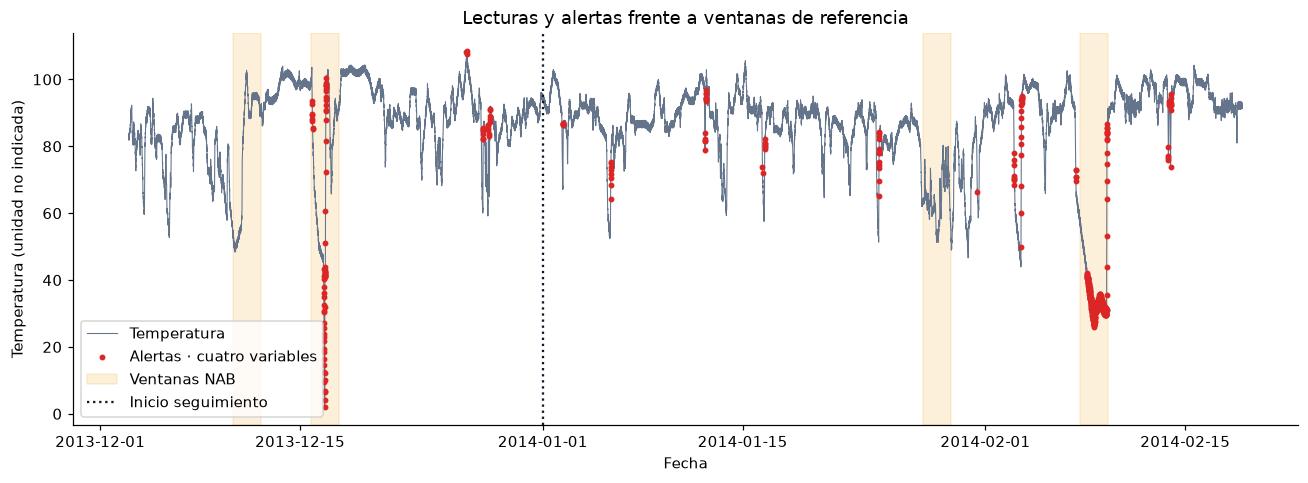

In [11]:
# Reto 3.2: misma muestra y corte que el modelo original; solo cambia el conjunto de variables.
modelo_valor = IsolationForest(n_estimators=150, max_samples=5000, random_state=2026, n_jobs=-1)
modelo_valor.fit(feat.loc[base, ["valor"]])
score_valor = pd.Series(-modelo_valor.score_samples(feat[["valor"]]), index=feat.index)
res_valor, diario_valor, ep_valor, alerta_valor = evaluar(score_valor, CORTE)
comparacion_variables = pd.DataFrame([
    {"modelo": "Cuatro variables", **escenarios[0.99][0]},
    {"modelo": "Solo valor", **res_valor}])
comparacion_variables["coincidencia_pct"] = 100 * comparacion_variables.en_ventana / comparacion_variables.episodios
display(comparacion_variables.round(6))
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df.index, df.value, color="#64748b", lw=0.7, label="Temperatura")
ax.scatter(feat.index[feat.alerta], feat.loc[feat.alerta, "valor"], s=8, color="#dc2626", label="Alertas · cuatro variables", zorder=3)
for j, (a, b) in enumerate(ventanas):
    ax.axvspan(a, b, color="#f59e0b", alpha=0.15, label="Ventanas NAB" if j == 0 else None)
ax.axvline(CORTE, color="#111827", ls=":", label="Inicio seguimiento")
ax.set(title="Lecturas y alertas frente a ventanas de referencia", ylabel="Temperatura (unidad no indicada)", xlabel="Fecha")
ax.legend(loc="lower left"); fig.tight_layout()
fig.savefig(RESULTADOS / "02_serie_y_alertas.png", dpi=150, bbox_inches="tight")
plt.show()


**Lectura de los resultados:** Solo valor produce 459 alertas y cuatro episodios frente a 495 y 17 con las cuatro variables; ambos cubren una ventana de dos. El gráfico conserva todas las temperaturas y contextualiza las alertas con los intervalos anotados.

**Respuesta:**

Uso el mismo corte del 01/01, las mismas 8.340 filas base, las mismas 14.112 filas de seguimiento y el mismo percentil 99. El modelo de una variable no recupera las primeras 12 filas: así la comparación tiene exactamente la misma muestra.

| Variables | Umbral propio | Alertas | Episodios | Episodios coincidentes | Coincidencia descriptiva | Ventanas cubiertas | Días fuera | Excedente diario |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cuatro variables | 0,606017 | 495 | 17 | 2 | 11,76 % | 1/2 | 8 | 6 |
| Solo valor | 0,589176 | 459 | 4 | 1 | 25,00 % | 1/2 | 4 | 0 |

Las cuatro variables generan **36 alertas y 13 episodios más**, porque la media, dispersión y cambio reciente permiten detectar movimientos que el valor aislado no caracteriza. Esto no demuestra que cada episodio adicional sea útil. Ambos modelos solo cubren **una de las dos ventanas**; dos coincidencias del modelo completo pertenecen a la misma ventana. La fracción 2/17 = 11,76 % frente a 1/4 = 25 % es descriptiva, **no precisión de fallas confirmadas**, porque las etiquetas no diagnostican cada episodio ni el resto se puede clasificar automáticamente como falso positivo.

El modelo `solo valor` merece servir de referencia sencilla por su menor carga. Elegiría entre ellos mediante revisión de utilidad de las alertas y costos en un periodo posterior, no por el mayor número de alertas ni solo por esta coincidencia histórica.

### Pregunta 3.3
Redacte una recomendación ejecutiva de ocho líneas con cifras, responsable, acción, límite y condición de revisión.

**Respuesta:**

Propongo un piloto de priorización de alertas, con revisión humana y sin paradas automáticas basadas solo en el modelo.  
El análisis guiado p99 registró 495 alertas, 17 episodios y 8 días fuera entre el 1 de enero y el 18 de febrero.  
Con un cupo estricto de una revisión diaria, p99,5 reduce la carga a 31 alertas y 3 episodios, sin excedente diario.  
Acepto ese umbral solo para el piloto: cubre una de dos ventanas y puede dejar sin atención cambios relevantes.  
El supervisor de mantenimiento asignará cada revisión; el técnico contrastará bitácora, sensor y estado del componente.  
El analista registrará tiempo de atención, resultado de la investigación y episodios pendientes, separando excedentes de cola final.  
La base contiene anomalías y las lecturas están correlacionadas; una coincidencia NAB o un score alto no confirma una avería.  
Revisaremos la regla al cerrar 14 días nuevos del piloto o antes si queda un episodio sin atender o se confirma un evento omitido.

## Entrega
Suba el notebook ejecutado a su GitHub personal en `semana12/` y comparta también el enlace a su Colab. Incluya las diez respuestas individuales y un cierre que distinga alerta estadística, investigación y falla demostrada. El cuestionario individual de la semana se rinde aparte.

## Verificación de resultados y archivos reproducibles

Las verificaciones comprueban coherencia entre la guía, los escenarios y las tablas exportadas. No prueban causalidad de las alertas ni sustituyen una evaluación operativa. Los CSV y gráficos quedan en `resultados/`.


In [12]:
# Comprobaciones sustantivas del flujo y exportación de las cifras usadas en las respuestas.
assert feat[VARIABLES].notna().all().all() and feat.index.is_monotonic_increasing
assert feat.index.is_unique and len(feat) == int(base.sum() + (~base).sum())
assert modelo.feature_names_in_.tolist() == VARIABLES
assert np.isclose(umbral, feat.loc[base, "score"].quantile(0.99))
assert len(ep) == int(ep.revisable.sum() + (~ep.revisable).sum())
assert ep.loc[ep.revisable].groupby("dia").size().le(CAPACIDAD_DIA).all()
assert sensibilidad.alertas.is_monotonic_decreasing
assert sensibilidad.apply(lambda r: r.episodios == r.revisables + r.cola, axis=1).all()
assert np.isclose(res_ampliado["umbral"], score_ampliado.loc[base_ampliada].quantile(0.99))
assert comparacion_base.loc[1, "lecturas"] == comparacion_base.loc[2, "lecturas"]
assert comparacion_variables.lecturas_seguimiento.nunique() == 1
assert ((diario.lic >= 0) & (diario.lsc <= 1) & (diario.lic <= diario.lsc)).all()
tablas_exportadas = {"calidad": pd.Series(calidad, name="resultado").to_frame(),
    "reporte_diario": diario, "episodios_seguimiento": ep,
    "sensibilidad_umbrales": sensibilidad, "cola_fifo": fifo, "ventanas_y_demoras": demoras,
    "comparacion_linea_base": comparacion_base, "diario_base_ampliada": diario_ampliado,
    "comparacion_variables": comparacion_variables}
for nombre, tabla in tablas_exportadas.items():
    tabla.to_csv(RESULTADOS / f"{nombre}.csv", index=True, encoding="utf-8-sig")
(RESULTADOS / "entorno.json").write_text(json.dumps(VERSIONES, indent=2), encoding="utf-8")
print("Verificaciones del análisis: correctas.")
print("Tablas exportadas:", len(tablas_exportadas), "· gráficos: 3.")


Verificaciones del análisis: correctas.
Tablas exportadas: 9 · gráficos: 3.


## Cierre: alerta, investigación y falla demostrada

Una **alerta estadística** significa que una lectura es rara respecto de la base y el umbral elegido. Una **investigación** contrasta esa señal con el funcionamiento del proceso y la instrumentación, y documenta lo encontrado. Una **falla demostrada** requiere evidencia física u operativa y diagnóstico técnico; no se deduce de una ventana NAB ni de la salida de Isolation Forest. Las hipótesis planteadas aquí conservan ese alcance.

El ejercicio sirve para priorizar revisión y reconocer sus limitaciones: p99 omitió una ventana completa, la base histórica incluye anomalías y la regla de capacidad es una simplificación retrospectiva. El piloto propuesto necesita datos nuevos y resultados de investigación para validar su utilidad.
